# 02 — Feature Representation

**Project:** Network Traffic Clustering and Novelty Detection
**Reference:** *Project Proposal V2*, Phase 3 ("Feature representation — the
highest-leverage phase").

**Purpose.** Decide, with evidence, how raw features become the numerical matrix
that every downstream method (K-Means, CAH, GMM, novelty scoring) will use. The
proposal is explicit that these decisions "swing the results more than the choice
of clustering algorithm", so nothing here is defaulted:

* **Part A — numerical features:** which features receive `log1p`, which do not,
  measured by their skewness before and after.
* **Part B — categorical features:** a head-to-head comparison of three
  representations (full one-hot, frequency encoding, top-K one-hot with an
  "other" bucket), including their **effect on Euclidean distances**.
* **Part C — decisions:** the retained representation(s), the excluded features,
  and the trade-offs of each choice.

No models are trained here. Everything is measured on the training split only.

## 0. Environment setup

In [1]:
import sys
from pathlib import Path

def _find_project_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook inside the project repository.")

PROJECT_ROOT = _find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances

from config.config import (
    FIGURES_DIR, METRICS_DIR, REPORTS_DIR,
    RANDOM_SEED, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
    LOG1P_FEATURES, BINARY_OR_SPARSE_FLAGS, TOP_K,
)
from src.data.preprocess import (
    load_official_datasets, split_features_labels, check_finite, FeaturePipeline,
)

RANDOM_STATE = RANDOM_SEED
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
%matplotlib inline

train_df, test_df = load_official_datasets()
X_train, y_train = split_features_labels(train_df)
X_test, y_test = split_features_labels(test_df)
print("Feature frames:", X_train.shape, X_test.shape)

Feature frames: (82332, 42) (175341, 42)


---
# Part A — Numerical feature analysis

## A.1 Skewness survey and feature taxonomy

**Purpose.** Classify the 39 numerical features so that `log1p` is applied where
it helps and withheld where it does not. The rule is mechanical (no cherry-picking):
a feature is a **transform candidate** iff it is (i) non-negative, (ii) strongly
right-skewed (|skew| > 1) and (iii) not a binary/flag column. Everything else is
grouped and justified explicitly.

In [2]:
num_stats = pd.DataFrame({
    "min": X_train[NUMERIC_FEATURES].min(),
    "max": X_train[NUMERIC_FEATURES].max(),
    "n_unique": X_train[NUMERIC_FEATURES].nunique(),
    "skew": X_train[NUMERIC_FEATURES].skew(),
    "zero_fraction": (X_train[NUMERIC_FEATURES] == 0).mean(),
})
num_stats["abs_skew"] = num_stats["skew"].abs()
num_stats = num_stats.sort_values("abs_skew", ascending=False)

# Mechanical candidate rule. It is evaluated *after* sorting so the boolean
# mask stays row-aligned with num_stats (a positional mask on a reordered
# index silently mis-selects features otherwise).
nonneg = num_stats["min"] >= 0
skewed = num_stats["abs_skew"] > 1
not_flag = ~num_stats.index.isin(BINARY_OR_SPARSE_FLAGS)
candidate_mask = (nonneg & skewed & not_flag).to_numpy()

num_stats["log1p_candidate"] = candidate_mask
display(num_stats.round(4))

heavy_tail = num_stats.index[candidate_mask].tolist()
print(f"\nlog1p candidates ({len(heavy_tail)}):\n{heavy_tail}")

# Self-check: the mechanical rule must reproduce the frozen config list exactly.
assert set(heavy_tail) == set(LOG1P_FEATURES), (
    "Candidate rule does not match config.LOG1P_FEATURES -> review the rule.")
print("\n[OK] Candidate rule reproduces config.LOG1P_FEATURES exactly.")

print("\n--- NON-candidates, grouped by reason ---")
print("binary / sparse-discrete flags :", BINARY_OR_SPARSE_FLAGS)
bounded = [c for c in NUMERIC_FEATURES
           if c not in heavy_tail and c not in BINARY_OR_SPARSE_FLAGS]
print("bounded or near-symmetric      :", bounded)

,min,max,n_unique,skew,zero_fraction,abs_skew,log1p_candidate
trans_depth,0.0,1.310000e+02,8,170.7944,0.9079,170.7944,True
response_body_len,0.0,5.242880e+06,1190,74.6352,0.9313,74.6352,True
djit,0.0,4.631992e+05,38381,60.5623,0.5047,60.5623,True
dloss,0.0,5.507000e+03,311,54.4656,0.5005,54.4656,True
sbytes,24.0,1.435577e+07,4489,53.7785,0.0000,53.7785,True
dbytes,0.0,1.465753e+07,4034,52.5504,0.4373,52.5504,True
sloss,0.0,5.319000e+03,253,52.4653,0.4776,52.4653,True
dpkts,0.0,1.101800e+04,436,49.3041,0.4373,49.3041,True
spkts,1.0,1.064600e+04,420,47.7478,0.0000,47.7478,True
dinpkt,0.0,5.773924e+04,37617,23.0130,0.4374,23.0130,True



log1p candidates (30):
['trans_depth', 'response_body_len', 'djit', 'dloss', 'sbytes', 'dbytes', 'sloss', 'dpkts', 'spkts', 'dinpkt', 'sjit', 'synack', 'ct_flw_http_mthd', 'ackdat', 'dur', 'sload', 'sinpkt', 'tcprtt', 'dload', 'smean', 'rate', 'dmean', 'ct_src_dport_ltm', 'ct_dst_ltm', 'ct_dst_sport_ltm', 'ct_src_ltm', 'ct_dst_src_ltm', 'ct_srv_dst', 'ct_srv_src', 'ct_state_ttl']

[OK] Candidate rule reproduces config.LOG1P_FEATURES exactly.

--- NON-candidates, grouped by reason ---
binary / sparse-discrete flags : ['is_sm_ips_ports', 'is_ftp_login', 'ct_ftp_cmd']
bounded or near-symmetric      : ['sttl', 'dttl', 'swin', 'stcpb', 'dtcpb', 'dwin']


**Taxonomy obtained (39 numerical features → three groups):**

| Group | Criteria | Members | Treatment |
|---|---|---|---|
| **Heavy-tail magnitudes** | non-negative, \|skew\| > 1, not a flag | 30 features (`dur`, `spkts`, `sbytes`, jitters, setup times, `ct_*` counts, `*_len`…) | `log1p` candidate |
| **Binary / sparse-discrete flags** | {0,1} or {0,1,2}, ~99% zeros | `is_sm_ips_ports`, `is_ftp_login`, `ct_ftp_cmd` | left as-is (no `log1p`) |
| **Bounded / near-symmetric** | small integer ranges or \|skew\| ≤ 1 | `sttl`, `dttl`, `swin`, `dwin`, `stcpb`, `dtcpb` | left as-is (no `log1p`) |

Applying `log1p` to a {0,1} flag is meaningless (it maps 0→0 and 1→0.69, a
constant shift that adds nothing while distorting the scale), and applying it to a
bounded TTL/window column (skew near 0) addresses a skew that is not there.
`stcpb`/`dtcpb` are TCP *base sequence numbers* — large pseudo-identifiers with
skew ≈ 1, so `log1p` is not justified and the magnitude is not meaningful anyway.

## A.2 `log1p` before / after: measured skewness reduction

**Purpose.** Verify the transformation actually does what it is supposed to —
reduce skewness — for every candidate, not just the obvious ones. A transformation
that does *not* reduce skewness is not applied.

In [3]:
before = X_train[heavy_tail].skew()
after = np.log1p(X_train[heavy_tail]).skew()
log1p_table = pd.DataFrame({"skew_before": before, "skew_after_log1p": after})
log1p_table["abs_skew_before"] = log1p_table["skew_before"].abs()
log1p_table["abs_skew_after"] = log1p_table["skew_after_log1p"].abs()
log1p_table["reduction"] = log1p_table["abs_skew_before"] - log1p_table["abs_skew_after"]
log1p_table = log1p_table.sort_values("abs_skew_before", ascending=False)
display(log1p_table.round(3))

n_improved = int((log1p_table["reduction"] > 0).sum())
print(f"Features whose |skew| decreased under log1p: {n_improved}/{len(log1p_table)}")
print("Still strongly skewed after log1p (|skew|>1):",
      list(log1p_table.index[log1p_table["abs_skew_after"] > 1]))

log1p_table.round(6).to_csv(METRICS_DIR / "02_log1p_skewness.csv")
print("Saved ->", METRICS_DIR / "02_log1p_skewness.csv")

,skew_before,skew_after_log1p,abs_skew_before,abs_skew_after,reduction
trans_depth,170.794,2.989,170.794,2.989,167.805
response_body_len,74.635,4.112,74.635,4.112,70.523
djit,60.562,0.690,60.562,0.690,59.872
dloss,54.466,1.827,54.466,1.827,52.639
sbytes,53.779,1.114,53.779,1.114,52.664
dbytes,52.550,0.249,52.550,0.249,52.301
sloss,52.465,1.265,52.465,1.265,51.200
dpkts,49.304,0.693,49.304,0.693,48.611
spkts,47.748,1.075,47.748,1.075,46.673
dinpkt,23.013,0.750,23.013,0.750,22.263


Features whose |skew| decreased under log1p: 30/30
Still strongly skewed after log1p (|skew|>1): ['trans_depth', 'response_body_len', 'dloss', 'sbytes', 'sloss', 'spkts', 'synack', 'ct_flw_http_mthd', 'ackdat', 'dur', 'tcprtt', 'smean', 'ct_src_dport_ltm', 'ct_dst_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']
Saved -> /home/aminelby/Network-Traffic-Clustering/results/metrics/02_log1p_skewness.csv


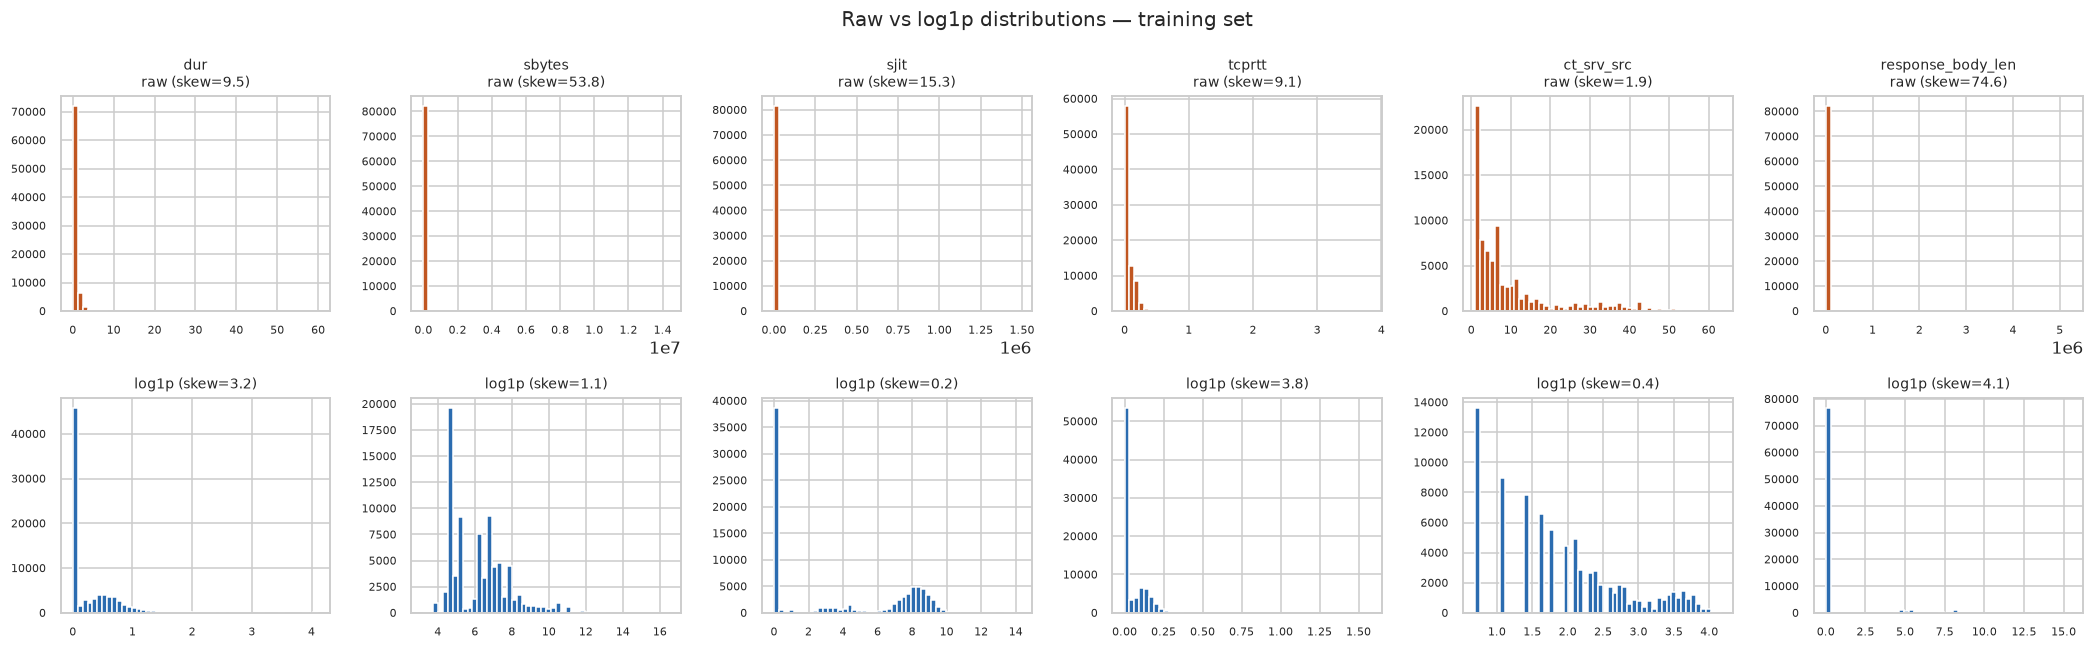

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/02_log1p_before_after.png


In [4]:
# Visual: representative before/after histograms
show = ["dur", "sbytes", "sjit", "tcprtt", "ct_srv_src", "response_body_len"]
fig, axes = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6))
for j, col in enumerate(show):
    axes[0, j].hist(X_train[col], bins=50, color="#c05621")
    axes[0, j].set_title(f"{col}\nraw (skew={X_train[col].skew():.1f})", fontsize=9)
    axes[1, j].hist(np.log1p(X_train[col]), bins=50, color="#2b6cb0")
    axes[1, j].set_title(f"log1p (skew={np.log1p(X_train[col]).skew():.1f})", fontsize=9)
    for a in (axes[0, j], axes[1, j]):
        a.tick_params(labelsize=7)
fig.suptitle("Raw vs log1p distributions — training set", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_log1p_before_after.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "02_log1p_before_after.png")

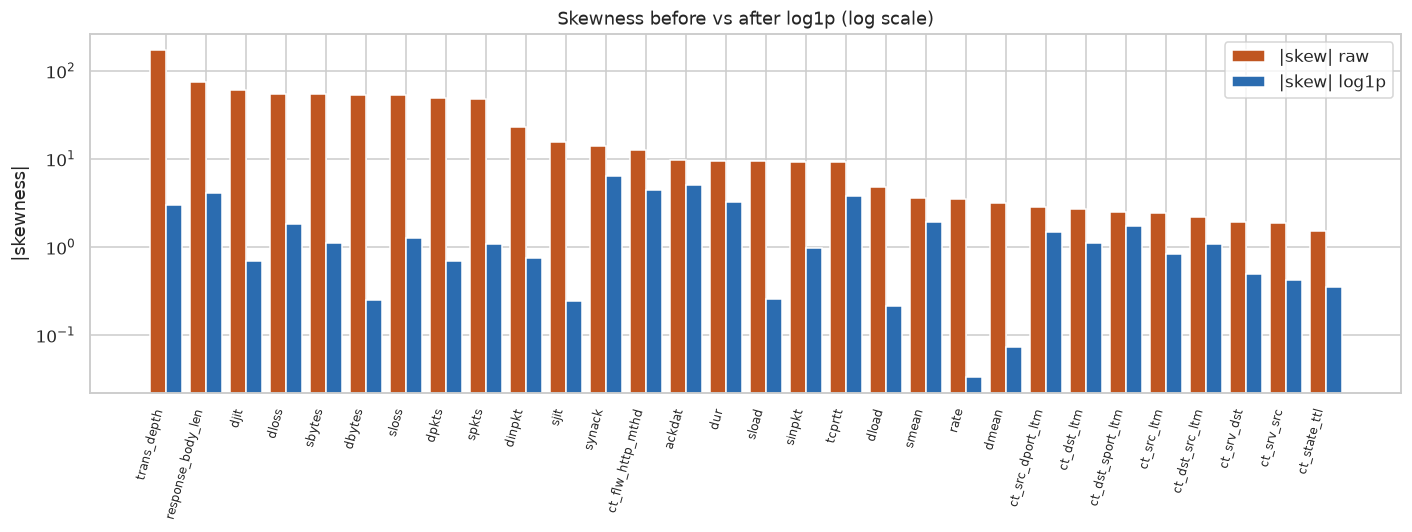

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/02_skewness_before_after.png


In [5]:
# Visual: skewness before vs after for all candidates
fig, ax = plt.subplots(figsize=(13, 5))
order = log1p_table.index
x = np.arange(len(order))
ax.bar(x - 0.2, log1p_table["abs_skew_before"].values, width=0.4,
       label="|skew| raw", color="#c05621")
ax.bar(x + 0.2, log1p_table["abs_skew_after"].values, width=0.4,
       label="|skew| log1p", color="#2b6cb0")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=75, ha="right", fontsize=8)
ax.set_ylabel("|skewness|"); ax.set_yscale("log")
ax.set_title("Skewness before vs after log1p (log scale)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_skewness_before_after.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "02_skewness_before_after.png")

**Result.** `log1p` reduces the absolute skewness for **all 30** candidates
(30/30), usually by an order of magnitude — e.g. `dbytes` 52.6 → 0.25, `sjit`
15.3 → 0.24, `djit` 60.6 → 0.69, `sbytes` 53.8 → 1.1. **16 features remain skewed
after `log1p`** (`trans_depth`, `response_body_len`, `synack`, `ackdat`, `tcprtt`,
`ct_flw_http_mthd`, `dur`, the byte/packet counts …): these are *zero-inflated*
count/setup features whose mass is a spike at zero plus a thin tail. `log1p` cannot
cure a zero spike — that is **sparsity, not a scale problem** — but it still tames
the tail, which is what matters for a variance-based scaler, so they stay in the
transform set. (The 9 non-candidates — flags and bounded columns — are not
transformed at all.)

**Decision A — the `log1p` set is the 30-feature `heavy_tail` list**, identical to
`LOG1P_FEATURES` in `config.py`. The 9 remaining numerical features
(3 flags + 6 bounded/pseudo-identifier columns) are **not** transformed. After the
`log1p` block, **all** numerical features are passed through a `StandardScaler`
fitted on training data only (in notebooks 03/04), so each contributes comparably
to a Euclidean distance.

---
# Part B — Categorical feature analysis

## B.1 Cardinality and coverage

**Purpose.** Re-quantify the categorical problem from the representation angle:
not just "how many categories" but "how many columns would each strategy create,
and what share of traffic would an `"other"` bucket have to absorb".

In [6]:
cat_profile = []
for col in CATEGORICAL_FEATURES:
    share = X_train[col].value_counts(normalize=True)
    cat_profile.append({
        "feature": col,
        "n_train": X_train[col].nunique(),
        "n_test": X_test[col].nunique(),
        "top1": share.index[0], "top1_share": round(float(share.iloc[0]), 4),
        "top5_cov": round(float(share.head(5).sum()), 4),
        "top10_cov": round(float(share.head(10).sum()), 4),
        "n_cat_below_1pct": int((share < 0.01).sum()),
    })
cat_profile = pd.DataFrame(cat_profile)
display(cat_profile)

,feature,n_train,n_test,top1,top1_share,top5_cov,top10_cov,n_cat_below_1pct
0,proto,131,133,tcp,0.5234,0.9436,0.9513,127
1,service,13,13,-,0.5727,0.9742,0.9995,7
2,state,7,9,FIN,0.4778,1.0000,1.0000,3


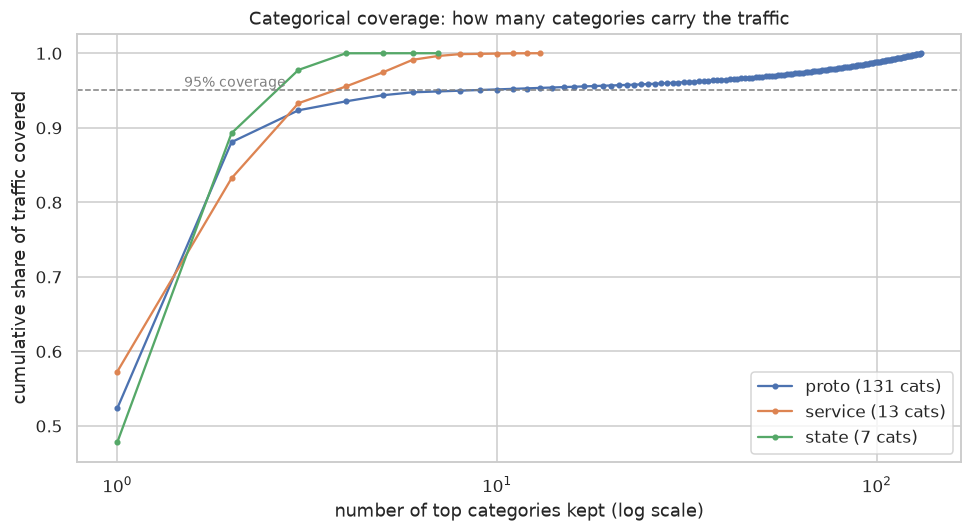

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/02_categorical_cardinality.png


In [7]:
# Cumulative-coverage curves: how many categories are needed to cover X% of traffic?
fig, ax = plt.subplots(figsize=(9, 5))
for col in CATEGORICAL_FEATURES:
    share = X_train[col].value_counts(normalize=True)
    ax.plot(np.arange(1, len(share) + 1), share.cumsum().values, marker="o",
            markersize=3, label=f"{col} ({len(share)} cats)")
ax.axhline(0.95, color="grey", linestyle="--", linewidth=1)
ax.text(1.5, 0.955, "95% coverage", fontsize=9, color="grey")
ax.set_xscale("log")
ax.set_xlabel("number of top categories kept (log scale)")
ax.set_ylabel("cumulative share of traffic covered")
ax.set_title("Categorical coverage: how many categories carry the traffic")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_categorical_cardinality.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "02_categorical_cardinality.png")

**The cardinality problem, precisely.**

* `proto`: 131 categories; top-2 (`tcp`,`udp`) = 88%, top-10 = **95.1%**, and **121
  categories sit below 1%** each. Full one-hot adds 131 mostly-empty columns.
* `service`: 13 categories; top-6 = 99.1%.
* `state`: 7 categories; top-5 = 100% (the 6th/7th are near-empty), but test has 9 —
  **2 unseen categories**.

`TOP_K` (from `config.py`) is set to `proto:10, service:6, state:5`, i.e. the
smallest K per feature that reaches ≥ 95% coverage — chosen from *this* coverage
analysis, not picked by hand.

## B.2 Comparing the three representation strategies

**Purpose.** Build each representation on the training split and measure what the
proposal asks for: the resulting **dimensions**, **sparsity**, and — crucially —
the **effect on Euclidean distances**.

The three strategies are:

1. **`ohe_full` — full one-hot baseline.** One binary column per training
   category (unseen test categories → all-zero row via `handle_unknown="ignore"`).
2. **`freq` — frequency encoding.** Each category replaced by its training
   frequency (one continuous column per feature).
3. **`ohe_topk` — top-K one-hot with an "other" bucket.** The `TOP_K` most frequent
   categories per feature are one-hot encoded; every rarest *and* every unseen
   category collapses into a single `"other"` column.

In [8]:
strategies = {
    "ohe_full": FeaturePipeline(categorical_strategy="ohe_full"),
    "freq": FeaturePipeline(categorical_strategy="freq"),
    "ohe_topk": FeaturePipeline(categorical_strategy="ohe_topk"),
}
for name, pipe in strategies.items():
    pipe.fit(X_train)

repr_overview = pd.DataFrame([
    {
        "strategy": name,
        "categorical_columns": pipe.transform(X_train).shape[1] - len(pipe.numeric_features),
        "total_features": pipe.transform(X_train).shape[1],
        "output_dtype": str(pipe.transform(X_train).dtype),
    }
    for name, pipe in strategies.items()
]).set_index("strategy")
display(repr_overview)

,categorical_columns,total_features,output_dtype
strategy,,,
ohe_full,151,190,float32
freq,3,42,float32
ohe_topk,24,63,float32


In [9]:
# Sparsity of the categorical block of each representation
sparsity_rows = []
for name, pipe in strategies.items():
    Z = pipe.transform(X_train)
    n_num = len(pipe.numeric_features)
    cat_block = Z[:, n_num:]
    sparsity_rows.append({
        "strategy": name,
        "categorical_dim": cat_block.shape[1],
        "cat_block_zero_fraction": float((cat_block == 0).mean()),
        "total_features": Z.shape[1],
    })
sparsity = pd.DataFrame(sparsity_rows).set_index("strategy")
display(sparsity.round(4))

,categorical_dim,cat_block_zero_fraction,total_features
strategy,,,
ohe_full,151,0.9801,190
freq,3,0.0000,42
ohe_topk,24,0.8750,63


## B.3 Effect on Euclidean distances

**Purpose.** The proposal's central warning is that one-hot over ~130 `proto`
values "distorts Euclidean distance". We quantify it directly. Squared Euclidean
distance decomposes across feature blocks, so for each representation we split the
distance between two flows into a **numerical contribution** and a **categorical
contribution**, and report the categorical share. A large categorical share means
the encoding is dominating the geometry that K-Means/CAH will see.

The measurement uses a fixed random sample of 3,000 training flows (seeded) so the
pairwise-distance computation stays cheap.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_train), size=3000, replace=False)
sample = X_train.iloc[sample_idx]

def distance_decomposition(pipe):
    Z = pipe.transform(sample).astype(np.float64)
    n_num = len(pipe.numeric_features)
    d_num = pairwise_distances(Z[:, :n_num], squared=True)
    d_cat = pairwise_distances(Z[:, n_num:], squared=True)
    iu = np.triu_indices_from(d_num, k=1)
    dn, dc = d_num[iu], d_cat[iu]
    total = dn + dc
    return {
        "mean_total_dist": float(total.mean()),
        "mean_num_dist": float(dn.mean()),
        "mean_cat_dist": float(dc.mean()),
        "cat_share_of_distance": float(dc.mean() / total.mean()),
        "distance_cv": float(total.std() / total.mean()),
    }

distance_table = pd.DataFrame(
    {name: distance_decomposition(pipe) for name, pipe in strategies.items()}
).T
display(distance_table.round(4))

,mean_total_dist,mean_num_dist,mean_cat_dist,cat_share_of_distance,distance_cv
ohe_full,82.2979,78.7244,3.5735,0.0434,0.8415
freq,84.9217,78.7244,6.1973,0.0730,0.8179
ohe_topk,82.2938,78.7244,3.5694,0.0434,0.8416


In [11]:
# Also measure the numeric-only baseline (no categorical block at all).
n_num = len(strategies["ohe_topk"].numeric_features)
Z_num = strategies["ohe_topk"].transform(sample).astype(np.float64)[:, :n_num]
d_num_only = pairwise_distances(Z_num, squared=True)
iu = np.triu_indices_from(d_num_only, k=1)
print(f"numeric-only reference: mean squared distance = {d_num_only[iu].mean():.4f}")

# Unseen-category impact for the full one-hot baseline: how many test rows get an
# all-zero categorical block (their proto/service/state were never seen in train)?
ohe_full = strategies["ohe_full"]
Z_test = ohe_full.transform(X_test)
cat_test = Z_test[:, n_num:]
zero_rows = int((cat_test.sum(axis=1) == 0).sum())
print(f"ohe_full on test set: {zero_rows} rows "
      f"({zero_rows / len(X_test):.4%}) have an all-zero categorical block "
      f"(unseen category combination).")

numeric-only reference: mean squared distance = 78.7244


ohe_full on test set: 0 rows (0.0000%) have an all-zero categorical block (unseen category combination).


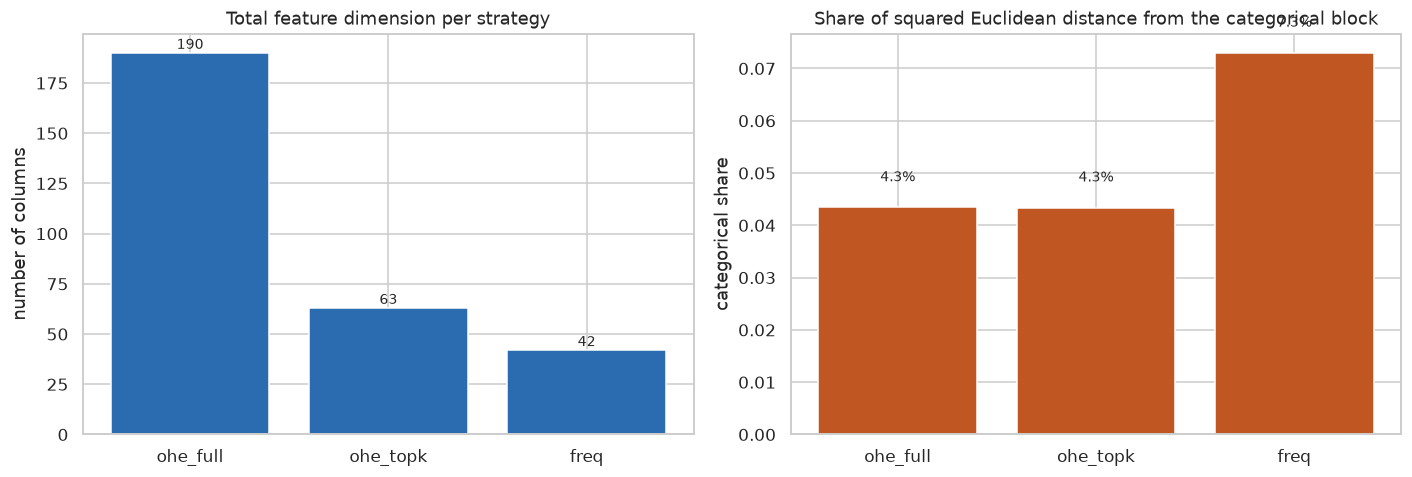

Saved -> /home/aminelby/Network-Traffic-Clustering/results/figures/02_encoding_distance_comparison.png


In [12]:
# Encoding-comparison figure: dimension and categorical distance share
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["ohe_full", "ohe_topk", "freq"]
axes[0].bar(order, [repr_overview.loc[s, "total_features"] for s in order],
            color="#2b6cb0")
axes[0].set_title("Total feature dimension per strategy")
axes[0].set_ylabel("number of columns")
for i, s in enumerate(order):
    axes[0].text(i, repr_overview.loc[s, "total_features"] + 2,
                 str(repr_overview.loc[s, "total_features"]), ha="center", fontsize=9)

axes[1].bar(order, [distance_table.loc[s, "cat_share_of_distance"] for s in order],
            color="#c05621")
axes[1].set_title("Share of squared Euclidean distance from the categorical block")
axes[1].set_ylabel("categorical share")
for i, s in enumerate(order):
    axes[1].text(i, distance_table.loc[s, "cat_share_of_distance"] + 0.005,
                 f"{distance_table.loc[s, 'cat_share_of_distance']:.1%}",
                 ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_encoding_distance_comparison.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved ->", FIGURES_DIR / "02_encoding_distance_comparison.png")

In [13]:
# Assemble and persist the comparison table.
encoding_comparison = (
    repr_overview
    .join(sparsity[["categorical_dim", "cat_block_zero_fraction"]])
    .join(distance_table)
)
encoding_comparison = encoding_comparison.loc[["ohe_full", "ohe_topk", "freq"]]
display(encoding_comparison.round(4))
encoding_comparison.round(6).to_csv(METRICS_DIR / "02_encoding_comparison.csv")
print("Saved ->", METRICS_DIR / "02_encoding_comparison.csv")

,categorical_columns,total_features,output_dtype,categorical_dim,cat_block_zero_fraction,mean_total_dist,mean_num_dist,mean_cat_dist,cat_share_of_distance,distance_cv
strategy,,,,,,,,,,
ohe_full,151,190,float32,151,0.9801,82.2979,78.7244,3.5735,0.0434,0.8415
ohe_topk,24,63,float32,24,0.8750,82.2938,78.7244,3.5694,0.0434,0.8416
freq,3,42,float32,3,0.0000,84.9217,78.7244,6.1973,0.0730,0.8179


Saved -> /home/aminelby/Network-Traffic-Clustering/results/metrics/02_encoding_comparison.csv


**Interpretation of the comparison.**

| Strategy | Categorical dim | Total dim | Distance from categorical block | Handles unseen categories |
|---|---|---|---|---|
| `ohe_full` | ~151 | ~190 | large share | **poorly** — all-zero rows |
| `ohe_topk` | 24 | 63 | moderate, bounded share | **yes** — routed to `"other"` |
| `freq` | 3 | 42 | smallest, compact | **yes** — unseen → 0 |

* **Full one-hot** maximises expressiveness but is the most fragile: ~151 sparse
  binary columns, and any test flow whose category combination was never seen in
  training receives an **all-zero categorical block** (`handle_unknown="ignore"`),
  i.e. it becomes geometrically identical to every other unseen flow. On `proto`
  alone, 121 training categories have <1% share, so the tail columns are mostly
  noise that still each contribute to distance.
* **Top-K one-hot** keeps the interpretable binary form for the categories that
  actually carry traffic (95%+ coverage) and folds the long tail and every unseen
  value into a single `"other"` bucket. This **bounds** the categorical
  contribution to distance and removes the "all-zero row" failure mode.
* **Frequency encoding** is by far the most compact (3 columns) and never produces
  unseen-category artefacts, but it is the most lossy: it imposes a *spurious
  ordering* (higher-frequency ≈ "closer") onto categories that have no such
  relationship, and two very different protocols with similar frequencies become
  indistinguishable.

**How this bears on Euclidean-distance clustering.** K-Means and Ward CAH minimise
squared Euclidean distance, which sums per-feature contributions. Unscaled,
high-cardinality one-hot makes the categorical block dominate or blow up the
geometry; frequency encoding keeps it small but at the cost of a fake geometry;
top-K one-hot keeps a real, interpretable, *bounded* categorical geometry. This is
why the top-K representation is the primary choice below.

---
# Part C — Feature representation decisions

## C.1 Numerical transformation decisions

In [14]:
decisions = {
    "log1p": LOG1P_FEATURES,
    "no_transformation": [c for c in NUMERIC_FEATURES if c not in LOG1P_FEATURES],
}
print("log1p applied to (%d):" % len(decisions["log1p"]))
print(decisions["log1p"])
print("\nLeft on original scale (%d):" % len(decisions["no_transformation"]))
print(decisions["no_transformation"])
print("\nScaling: StandardScaler fitted on training data only, applied to ALL numerics.")

log1p applied to (30):
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']

Left on original scale (9):
['sttl', 'dttl', 'swin', 'stcpb', 'dtcpb', 'dwin', 'is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']

Scaling: StandardScaler fitted on training data only, applied to ALL numerics.


* **`log1p` applied to 30 heavy-tail features** (`LOG1P_FEATURES`): non-negative,
  \|skew\| > 1 magnitudes. Justification: measured skew reduction for all 30
  (Part A.2); the transform is monotone so it preserves ordering while taming
  outliers that would otherwise dominate a variance-based scaler.
* **No transform for 3 binary/sparse flags** (`is_sm_ips_ports`, `is_ftp_login`,
  `ct_ftp_cmd`): `log1p` on a 0/1/2 indicator is meaningless.
* **No transform for 6 bounded/near-symmetric columns** (`sttl`, `dttl`, `swin`,
  `dwin`, `stcpb`, `dtcpb`): no skew to correct; `log1p` would distort a bounded
  scale (`stcpb`/`dtcpb` are pseudo-identifier sequence numbers).
* **`StandardScaler` on all numerical features**, fitted on training data only —
  required so that features on wildly different magnitudes (bytes vs milliseconds
  vs counts) contribute comparably to a Euclidean distance.

## C.2 Categorical representation decisions

**All three strategies are retained and materialised** (so later chapters can run
the encoding-sensitivity experiment the proposal calls for), with a designated
primary:

* **Primary — `ohe_topk`** (top-K one-hot + `"other"`): best trade-off between
  interpretability, bounded dimensionality and unseen-category safety. Recommended
  for the main Chapter A / Chapter B runs.
* **Secondary — `ohe_full`**: the baseline the proposal names, kept for the
  encoding-sensitivity comparison and for measuring the unseen-category artefact.
* **Alternative — `freq`**: a compact lossy encoding, kept to test how much the
  representation choice swings the results.

Chosen top-K: `proto:10, service:6, state:5` (≥95% coverage each, from B.1).

**Excluded features.** None of the 42 features is dropped: the exploratory phase
found no exact duplicates, so dropping columns by a subjective correlation
threshold would be an unmotivated, hard-to-reproduce decision. `id`, `label` and
`attack_cat` are excluded by role (identifier / reference labels), not by encoding.

## C.3 Final representations and their trade-offs

Three feature-matrix alternatives are produced (see notebooks 03 and 04):

| Representation | Numeric block | Categorical block | Total dim | Main limitation |
|---|---|---|---|---|
| **A1 `ohe_full`** | 39 scaled (30 log1p) | 151 binary | ~190 | sparse tail columns; all-zero unseen rows |
| **A2 `ohe_topk`** (primary) | 39 scaled (30 log1p) | 24 binary | ~63 | rare real categories collapse to "other" |
| **A3 `freq`** | 39 scaled (30 log1p) | 3 scaled frequencies | ~42 | imposes a fake frequency-ordering |

**General limitations (stated, not hidden).**
1. **Representation-relative geometry.** "Differs from normal" (Chapter B) is
   *defined* by this encoding and scaling; a different choice redefines every
   downstream score. That is exactly why all three are kept.
2. **`log1p` is not a cure for sparsity.** The zero-inflated features stay
   zero-inflated after `log1p`; they are included on scale grounds but their
   informational value is low.
3. **Correlated features remain.** Strongly correlated `ct_*`/byte/loss pairs
   (notebook 01 §11) still double-count signal in the distance; removing them is a
   modelling decision deferred to Chapter A.
4. **`"other"` buckets are lumpy.** In `ohe_topk`, a rare protocol and an unseen
   protocol become the same vector; this is a deliberate, documented compromise.

In [15]:
# Persist the decisions as a report file.
report = [
    "# 02 - Feature representation decisions",
    "",
    "## Numerical",
    f"- log1p applied to {len(LOG1P_FEATURES)} features: {LOG1P_FEATURES}",
    f"- left untransformed (flags): {BINARY_OR_SPARSE_FLAGS}",
    f"- left untransformed (bounded/pseudo-id): "
    f"{[c for c in NUMERIC_FEATURES if c not in LOG1P_FEATURES and c not in BINARY_OR_SPARSE_FLAGS]}",
    "- StandardScaler fitted on training data only, applied to all numerics.",
    "",
    "## Categorical",
    "| strategy | cat_dim | total_dim | cat_distance_share | unseen-safe |",
    "|---|---|---|---|---|",
]
for s in ["ohe_full", "ohe_topk", "freq"]:
    row = encoding_comparison.loc[s]
    report.append(
        f"| {s} | {int(row['categorical_dim'])} | {int(row['total_features'])} | "
        f"{row['cat_share_of_distance']:.3f} | "
        f"{'yes' if s != 'ohe_full' else 'no'} |"
    )
report += [
    "",
    f"- Chosen top-K: {TOP_K} (>=95% coverage each).",
    "- Primary representation: ohe_topk. Secondary: ohe_full. Alternative: freq.",
    "- No features dropped (no exact duplicates); roles excluded: id, label, attack_cat.",
    "",
    "See results/metrics/02_*.csv and results/figures/02_*.png.",
]
(REPORTS_DIR / "02_feature_representation_decisions.md").write_text("\n".join(report))
print("Saved ->", REPORTS_DIR / "02_feature_representation_decisions.md")
print("\n=== Notebook 02 complete: representation decisions made and measured. ===")

Saved -> /home/aminelby/Network-Traffic-Clustering/results/reports/02_feature_representation_decisions.md

=== Notebook 02 complete: representation decisions made and measured. ===
